# Make predictions

In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import sys
sys.path.append('../../../python_modules/')
# plt.rcdefaults() 
plt.rcParams['figure.dpi'] = 200
plt.rcParams['pdf.fonttype'] = '42'

from domino.models.domino_models import DominoSingleOutput
from domino.utils import tools
from domino.data.domino_data import GenomeDataset
# import pytorch_lightning as pl
from domino.data.data import preprocess_data, process_bed_file_df
from domino.utils.tools import seq_from_df
import matplotlib.ticker as mticker
from generic_plotting_functions import *

import scipy.stats as stats
import pandas as pd
import os
import numpy as np

import fanc
import fanc.plotting as fancplot

from domino.utils.plotting import plot_attribution

import coolbox
from coolbox.api import *

from tqdm import tqdm

In [2]:
model_dir = '/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/'

TRAIN_df = pd.read_csv(os.path.join(model_dir, 'TRAIN_df.csv'))
VAL_df = pd.read_csv(os.path.join(model_dir, 'VAL_df.csv'))
TEST_df = pd.read_csv(os.path.join(model_dir, 'TEST_df.csv'))

In [3]:
print(stats.spearmanr(TRAIN_df.demeaned_ins_score_1, TRAIN_df.pred))
print(stats.spearmanr(VAL_df.demeaned_ins_score_1, VAL_df.pred))
print(stats.spearmanr(TEST_df.demeaned_ins_score_1, TEST_df.pred))

SignificanceResult(statistic=0.8365473846366163, pvalue=0.0)
SignificanceResult(statistic=0.8215030765883342, pvalue=0.0)
SignificanceResult(statistic=0.775940343784495, pvalue=0.0)


In [4]:
print(stats.pearsonr(TRAIN_df.demeaned_ins_score_1, TRAIN_df.pred))
print(stats.pearsonr(VAL_df.demeaned_ins_score_1, VAL_df.pred))
print(stats.pearsonr(TEST_df.demeaned_ins_score_1, TEST_df.pred))

PearsonRResult(statistic=0.8020401261237734, pvalue=0.0)
PearsonRResult(statistic=0.7758833786609644, pvalue=0.0)
PearsonRResult(statistic=0.6845917921783696, pvalue=0.0)


In [5]:
# load model
model_checkpoint_path = f"{model_dir}/checkpoint/{os.listdir(model_dir + '/checkpoint')[0]}"
model = DominoSingleOutput.load_from_checkpoint(model_checkpoint_path, activation='gelu')
model.eval()

resolution=200
num_merged=11
delta=2
ws=1
 
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'
data = fanc.load(f'{data_dir}/mcools/new_nc14_embryo_merged_all_{num_merged}.mcool@{resolution}')

fc dim 206
extra dim 6


In [6]:
ws = 1
mean_scaling_window=10


nc14_rep_1_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ws}kb.bed'
nc14_ins_1 = process_bed_file_df(nc14_rep_1_ins_path, 'ins_score')
nc14_ins_1["demeaned_ins_score"] = nc14_ins_1["ins_score"] - nc14_ins_1["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

nc14_rep_2_ins_path = f'/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files/nc14_embryo_merged_form_fed_8.resolution=200bp.insulation_{ws}kb.bed'
nc14_ins_2 = process_bed_file_df(nc14_rep_2_ins_path, 'ins_score')
nc14_ins_2["demeaned_ins_score"] = nc14_ins_2["ins_score"] - nc14_ins_2["ins_score"].rolling(2*mean_scaling_window+1, center=True).mean()

In [7]:
def get_demeaned_ins_track(row, ins, ins_score_context_bin_width=15000//200):
    chrom, start, end = row.chrom, row.start, row.end
    # get insulation around boundary of interest
    tmp = ins.query('chrom == @chrom and start == @start and end==@end')
    i = tmp.index.item()
    idxs_pos = np.arange(i-ins_score_context_bin_width, i+ins_score_context_bin_width+1)
    y_pos = np.array([np.array(ins['demeaned_ins_score'][idx_arr]) for idx_arr in idxs_pos]) # context with middle bin
    return y_pos

In [8]:
import numpy as np
from scipy.ndimage import binary_dilation
from scipy.stats import pearsonr, spearmanr

def masked_correlation_1d(a, b, w=2):
    if len(a) != len(b):
        raise ValueError("Arrays must have same length")

    # Non-finite in either array
    bad = ~(np.isfinite(a) & np.isfinite(b))

    # Expand by w positions on each side
    structure = np.ones(2*w + 1, dtype=bool)
    bad_expanded = binary_dilation(bad, structure=structure)

    keep = ~bad_expanded

    x = a[keep]
    y = b[keep]

    if len(x) < 10 or len(y) < 10:
        return None, None, keep

    return (
        pearsonr(x, y).statistic,
        spearmanr(x, y).statistic,
        keep,
    )

In [9]:
import pysam
from domino.utils.tools import seq_from_df
def get_predicted_track(boundary, ins_score_context_bin_width=10, resolution=200, bp_radius=15_000):
    ins_ws=1
    ins_dir = "/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/insulations/insulation_files"
    ins1_path = f"{ins_dir}/new_nc14_embryo_merged_all_11.resolution=200bp.insulation_{ins_ws}kb.bed"
    ins_score1 = process_bed_file_df(ins1_path, target_col='ins_score')

    # get insulation around boundary of interest
    chrom, start, end = boundary
    tmp = ins_score1.query('chrom == @chrom and start == @start and end==@end')
    bin_radius = bp_radius // resolution
    locus_df = ins_score1.iloc[tmp.index.item() - bin_radius:tmp.index.item() + bin_radius + 1]
    
    genome_path = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing/annotations/dm6.fa'
    genome_fasta = pysam.FastaFile(genome_path)

    locus_df['direction'] = ["+"] * len(locus_df)
    locus_df.reset_index(inplace=True, drop=True)
    seqs = seq_from_df(genome_fasta, locus_df, DNA_context_length=16*200)
    
    predictions = model(seqs.to('cuda'))
    predictions = predictions.cpu().detach().flatten()
    
    x, y = np.arange(len(predictions)), predictions
    return x, y

## Compute pred-rep correlations

In [10]:
import numpy as np
from scipy.ndimage import binary_dilation
from scipy.stats import pearsonr, spearmanr

def masked_correlation_1d(a, b, w=2):
    """
    """
    if len(a) != len(b):
        raise ValueError("Arrays must have same length")

    # Non-finite in either array
    bad = ~(np.isfinite(a) & np.isfinite(b))

    # Expand by w positions on each side
    structure = np.ones(2*w + 1, dtype=bool)
    bad_expanded = binary_dilation(bad, structure=structure)

    keep = ~bad_expanded

    x = a[keep]
    y = b[keep]

    if len(x) < 10 or len(y) < 10:
        return None, None, keep

    return (
        pearsonr(x, y).statistic,
        spearmanr(x, y).statistic,
        keep,
    )

In [11]:
nc14_bound_df = pd.read_csv('/scratch/gpfs/PRITYKIN/brendan/domino/output/06_12_2026_final_nc14_no_mig/DominoSingleOutput_10_16_2_1_200_32_False_False_42_0.001_plateau_5_1_512_5_256_5_4_64_gelu/final_nc14_boundaries_df.bound_score_gt_1.csv')
nc14_bound_df = nc14_bound_df.query('has_stripe_at_bound == False')
nc14_bound_df = nc14_bound_df.drop_duplicates(['chrom', 'start', 'end'])

examples_to_test = TEST_df.merge(nc14_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])
examples_to_train = TRAIN_df.merge(nc14_bound_df[['chrom', 'start', 'end']], on=['chrom', 'start', 'end']).drop_duplicates(['chrom', 'start', 'end'])

test_boundaries = examples_to_test.reset_index(drop=True)
train_boundaries = examples_to_train.reset_index(drop=True)

In [14]:
# from tqdm import tqdm
# test_predicted_tracks = []
# for i, row in tqdm(test_boundaries.iterrows(), total=len(test_boundaries), desc="Processing rows"):
#     boundary = (row.chrom, row.start, row.end)
#     _, preds = get_predicted_track(boundary)
#     test_predicted_tracks.append(preds.numpy())

In [15]:
# np.save('nc14_test_regions_predictions.npy', np.array(test_predicted_tracks))

In [16]:
# from tqdm import tqdm
# train_predicted_tracks = []
# for i, row in tqdm(train_boundaries.iterrows(), total=len(train_boundaries), desc="Processing rows"):
#     boundary = (row.chrom, row.start, row.end)
#     _, preds = get_predicted_track(boundary)
#     train_predicted_tracks.append(preds.numpy())

In [17]:
# np.save('nc14_train_regions_predictions.npy', np.array(train_predicted_tracks))

## Correlation between pred (train and test)

In [12]:
train_predicted_arr = np.load('./nc14_train_regions_predictions.npy')
test_predicted_arr = np.load('./nc14_test_regions_predictions.npy')

In [13]:
def get_track_correlations_pred(pred_arr, boundaries):
    pearson_correlations = []
    spearman_correlations = []
    
    for i, row in tqdm(boundaries.iterrows(), total=len(boundaries), desc="Processing rows"):
        # row = examples_to_test.iloc[100]
        y1 = get_demeaned_ins_track(row, nc14_ins_1)
        
        pred = pred_arr[i]
    
        pcc, scc, _ = masked_correlation_1d(y1, pred)
    
        pearson_correlations.append(pcc)
        spearman_correlations.append(scc)

    return pearson_correlations, spearman_correlations

In [26]:
_, train_spearmans = get_track_correlations_pred(train_predicted_arr, train_boundaries)
_, test_spearmans = get_track_correlations_pred(test_predicted_arr, test_boundaries)

Processing rows: 100%|██████████| 685/685 [00:09<00:00, 70.16it/s]


In [27]:
train_boundaries['pred_spearman'] = train_spearmans
test_boundaries['pred_spearman'] = test_spearmans

## Correlation between replicates insulation (test)

In [28]:
from tqdm import tqdm 

rep_ins_pearson_correlations = []
rep_ins_spearman_correlations = []

for i, row in tqdm(test_boundaries.iterrows(), total=len(test_boundaries), desc="Processing rows"):
    # row = test_boundaries.iloc[100]
    y1 = get_demeaned_ins_track(row, nc14_ins_1)
    y2 = get_demeaned_ins_track(row, nc14_ins_2)

    pcc, scc, _ = masked_correlation_1d(y1, y2)

    rep_ins_pearson_correlations.append(pcc)
    rep_ins_spearman_correlations.append(scc)

Processing rows: 100%|██████████| 685/685 [00:18<00:00, 37.30it/s]


In [29]:
test_boundaries['rep_spearman'] = rep_ins_spearman_correlations

## Correlation between replicates maps (test)

In [30]:
import glob
import cooler 

resolution=200
ws=1 # insulation window size
delta=2
demean_context_bin_width = 10 # insulation context window size
boundary_length=200
data_dir = '/scratch/gpfs/PRITYKIN/brendan/microc_preprocessing'

def get_file(folder, tag):
    file = glob.glob(f'{folder}/*{tag}')
    # print(file)
    assert (len(file) == 1)
    return file[0]

clr1_file = get_file(f'{data_dir}/mcools/', 'new_nc14*11.mcool')
clr2_file = get_file(f'{data_dir}/mcools/', 'nc14*form_fed*.mcool')

clr1 = cooler.Cooler(clr1_file + f'::/resolutions/{resolution}')
clr2 = cooler.Cooler(clr2_file + f'::/resolutions/{resolution}')

In [32]:
OFFSET=15_000

matrix_pearsons = []
matrix_spearmans = []

for i, row in tqdm(test_boundaries.iterrows(), total=len(test_boundaries), desc="Processing rows"):

    # get 30.2 KB region around these boundaries
    mat1 = clr1.matrix(balance=True).fetch(f"{row.chrom}:{row.start - OFFSET}-{row.end+OFFSET}")
    mat2 = clr2.matrix(balance=True).fetch(f"{row.chrom}:{row.start - OFFSET}-{row.end+OFFSET}")
    
    mask = np.isfinite(mat1) & np.isfinite(mat2) 
    
    x = mat1[mask]
    y = mat2[mask]

    # compute PCC and SCC between maps (must be finite)
    pcc, _ = stats.pearsonr(x, y)
    scc, _ = stats.spearmanr(x, y)
    
    matrix_pearsons.append(pcc)
    matrix_spearmans.append(scc)

Processing rows: 100%|██████████| 685/685 [00:39<00:00, 17.28it/s]


In [33]:
test_boundaries['matrix_spearman_res_200'] = matrix_spearmans

## Final plot

In [34]:
train_boundaries.query('pred_spearman.isnull()')

,chrom,start,end,ins_score_1,copy_index_1,ins_score_2,copy_index_2,boundary,demeaned_ins_score_1,demeaned_ins_score_2,direction,pred,pred_spearman
1283,chr2L,23394801,23395000,0.363514,116974,-0.227554,116974,1,0.123751,-0.145579,+,-0.310092,NaN
2721,chr3L,25304201,25304400,0.149079,370525,-0.252577,370525,1,0.017648,-0.179314,+,-0.176357,NaN
2727,chr3L,26153201,26153400,0.224419,374770,-0.624179,374770,1,-0.226476,-0.767310,+,-0.089770,NaN
2741,chr3R,3488801,3489000,-0.081773,402000,-0.249364,402000,1,-0.637586,-0.256506,+,-0.620215,NaN
5940,chrY,892001,892200,-1.266933,673964,-1.005243,673964,1,-1.013677,inf,+,-0.335557,NaN
5951,chrY,2479401,2479600,-0.218538,681901,-0.772002,681901,1,-0.341562,inf,+,-0.256394,NaN
5952,chrY,2493001,2493200,0.415904,681969,0.783618,681969,1,0.042317,inf,+,-0.020571,NaN
5956,chrY,2835601,2835800,-2.126032,683682,-2.208267,683682,1,-2.060581,inf,+,-0.210452,NaN


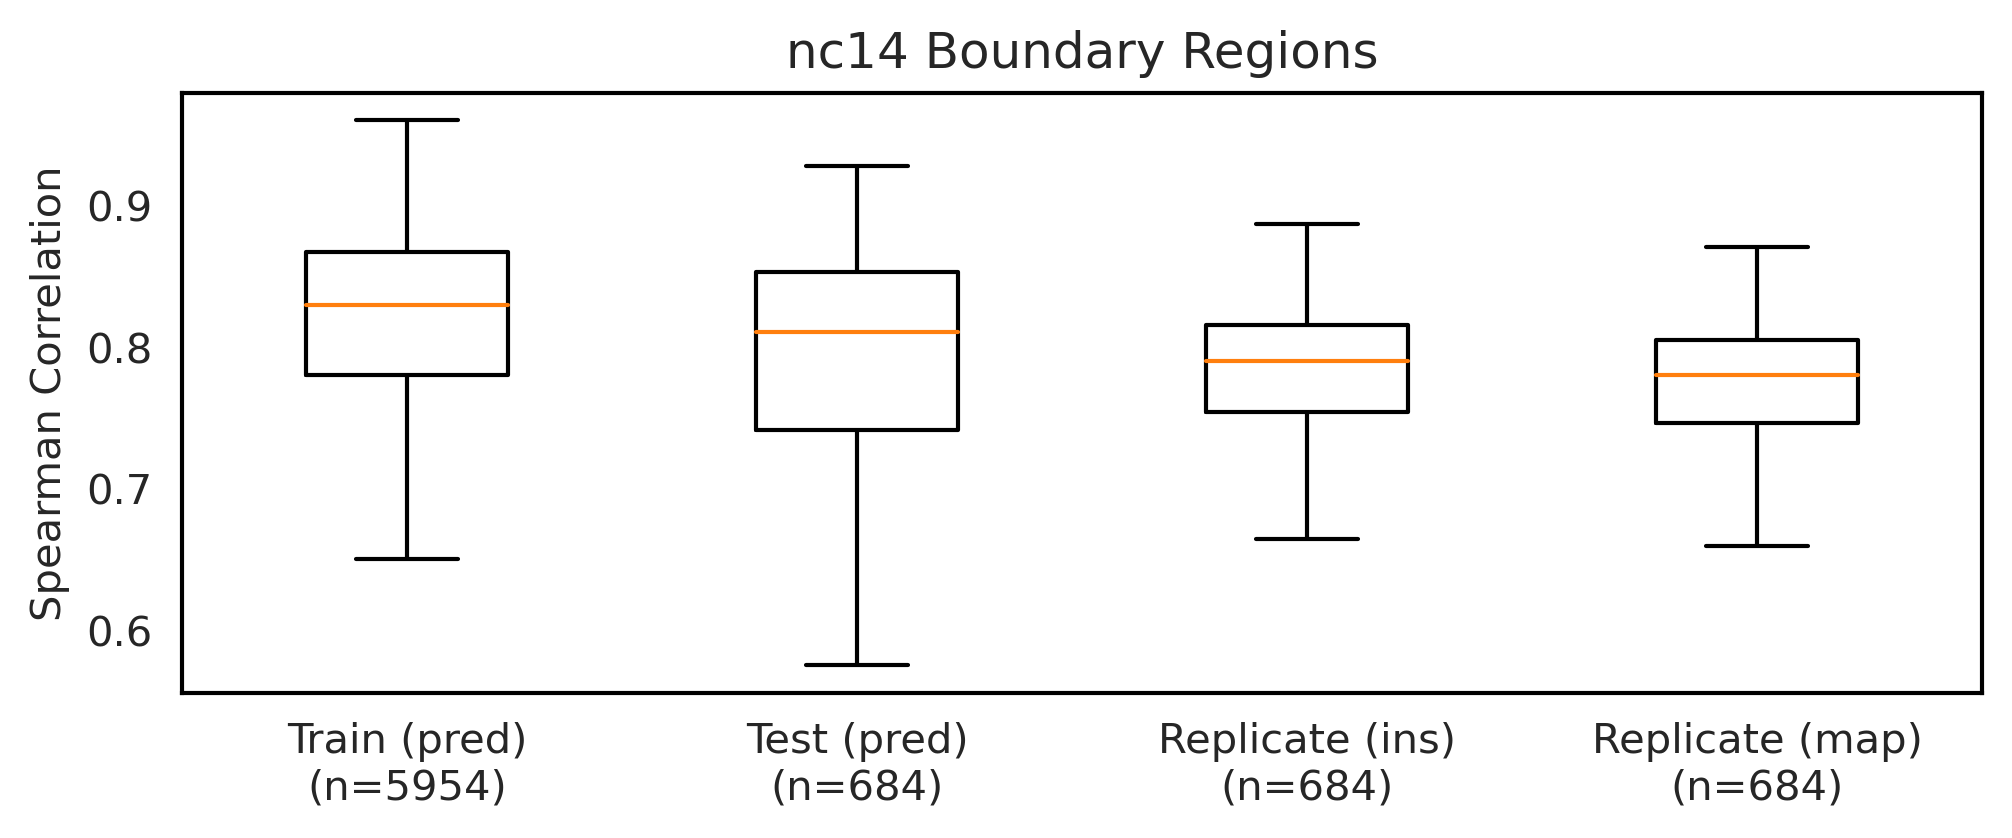

In [37]:
import matplotlib.pyplot as plt

train_pred = train_boundaries.query('~pred_spearman.isnull()').pred_spearman
test_pred = test_boundaries.query('~rep_spearman.isnull()').pred_spearman
test_ins = test_boundaries.query('~rep_spearman.isnull()').rep_spearman
test_map = test_boundaries.query('~rep_spearman.isnull()').matrix_spearman_res_200

fig, ax = init_subplots_exact(1,1,x_ratios=[1.5], y_ratios=[0.5], dpi=300)

ax.boxplot(
    [train_pred, test_pred, test_ins, test_map],
    labels = [f"Train (pred)\n(n={len(train_pred)})", f"Test (pred)\n(n={len(test_pred)})", f"Replicate (ins)\n(n={len(test_ins)})", f"Replicate (map)\n(n={len(test_map)})"],
    # flierprops=dict(markersize=1),
    showfliers=False
)

for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1)
# ax.set_xticklabels(["Train", "Test", "Replicate (ins)", "Replicate (map)"])
# plt.ylim([0.5, 1])
ax.set_ylabel("Spearman Correlation")
ax.set_title("nc14 Boundary Regions")
ax.grid(False)
plt.show()

In [38]:
print('Medians')
print('Train (pred)', train_pred.median())
print('Test (pred)', test_pred.median())
print('Test (rep ins)', test_ins.median())
print('Test (rep map)', test_map.median())

print()

print('Means')
print('Train (pred)', train_pred.mean())
print('Test (pred)', test_pred.mean())
print('Test (rep ins)', test_ins.mean())
print('Test (rep map)', test_map.mean())


Medians
Train (pred) 0.8301533635413034
Test (pred) 0.8110996863018473
Test (rep ins) 0.7905629139072847
Test (rep map) 0.7804856094275303

Means
Train (pred) 0.8140311584719482
Test (pred) 0.779357169213954
Test (rep ins) 0.7798432099192503
Test (rep map) 0.7699791402291092
